In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("combined_chronic_delays.csv")

# Convert numerical columns
numeric_cols = [
    "total_operations",
    "delayed_operations",
    "percentage_delay",
    "average_delay_minutes",
    "departure_time"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Extract departure hour from HHMM format
df["departure_hour"] = df["departure_time"] // 100
df.loc[~df["departure_hour"].between(0, 23),
       "departure_hour"] = np.nan

# Separate origin and destination airports
df[["origin", "destination"]] = (
    df["origin_destination"].str.split("-", n=1, expand=True)
)

# Month order
month_order = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

df["month_short"] = df["month"].astype(str).str[:3].str.title()

sns.set_theme(style="whitegrid")


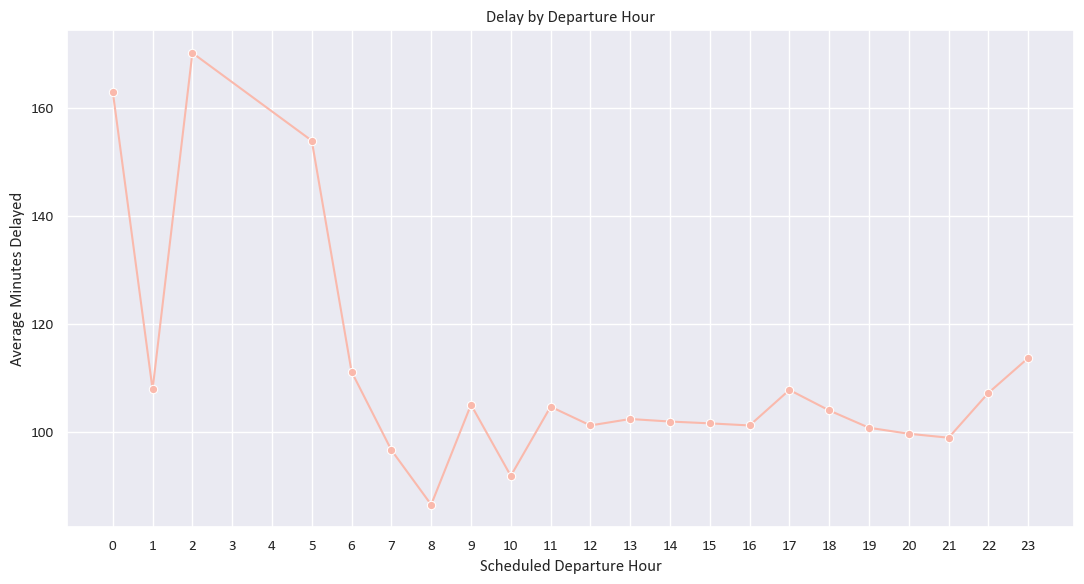

    departure_hour        mean  count
0              0.0  163.080000      3
1              1.0  107.856667      6
2              2.0  170.270000      1
3              5.0  153.990000      8
4              6.0  111.125789     19
5              7.0   96.593871     62
6              8.0   86.474321     81
7              9.0  105.014651     86
8             10.0   91.817213    122
9             11.0  104.645942    138
10            12.0  101.170450    200
11            13.0  102.363197    244
12            14.0  101.893904    356
13            15.0  101.557300    437
14            16.0  101.165614    586
15            17.0  107.753356    888
16            18.0  103.953151    933
17            19.0  100.741413    998
18            20.0   99.626008    794
19            21.0   98.894828    495
20            22.0  107.211648    267
21            23.0  113.683929     28


In [32]:
hourly = (
    df.groupby("departure_hour")["average_delay_minutes"]
    .agg(["mean", "count"])
    .reset_index()
)

plt.figure(figsize=(11, 6))

sns.set_theme(font="Calibri")

sns.lineplot(
    data=hourly,
    x="departure_hour",
    y="mean",
    marker="o",
    color = "#fab9ac"
)

plt.xticks(range(0, 24))
plt.title("Delay by Departure Hour")
plt.xlabel("Scheduled Departure Hour")
plt.ylabel("Average Minutes Delayed")
plt.tight_layout()
plt.savefig("delay_by_departure_hour.png")
plt.show()

print(hourly)


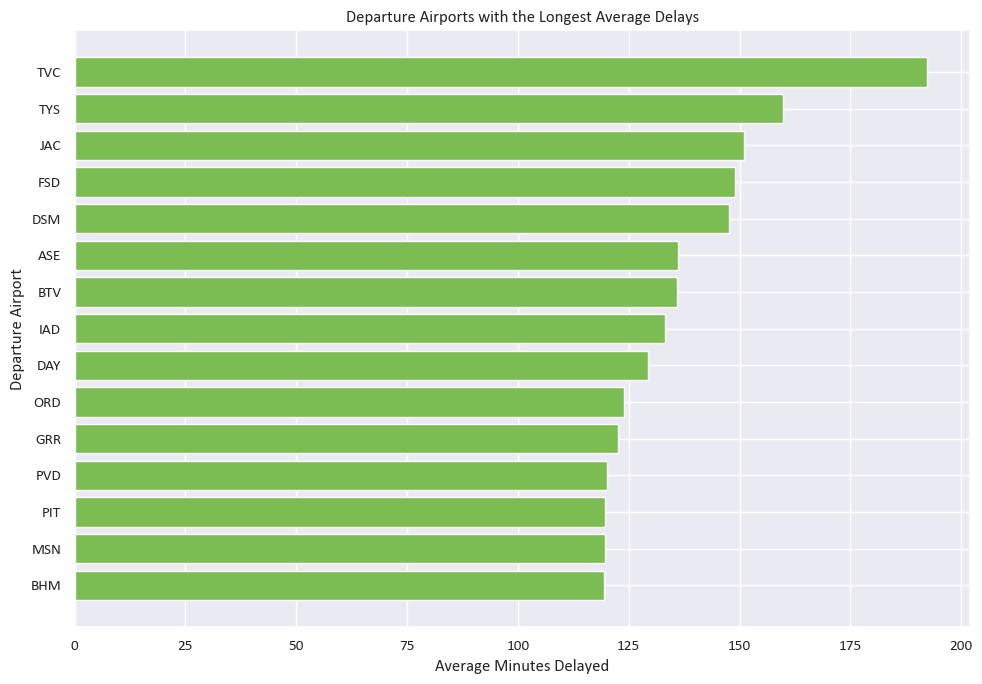

        avg_delay  flights
origin                    
BHM        119.47       13
MSN        119.56       14
PIT        119.65       30
PVD        120.00       13
GRR        122.63       21
ORD        124.04      527
DAY        129.36       11
IAD        133.09       17
BTV        136.00       16
ASE        136.04       30
DSM        147.63       18
FSD        148.90       10
JAC        150.93       10
TYS        159.87       16
TVC        192.37       18


In [33]:
airport_delays = (
    df.groupby("origin")
    .agg(
        avg_delay=("average_delay_minutes", "mean"),
        flights=("average_delay_minutes", "count")
    )
    .query("flights >= 10")
    .sort_values("avg_delay", ascending=False)
    .head(15)
    .sort_values("avg_delay")
)

plt.figure(figsize=(10, 7))

plt.barh(
    airport_delays.index,
    airport_delays["avg_delay"],
    color = "#7bbc53"
)

plt.title("Departure Airports with the Longest Average Delays")
plt.xlabel("Average Minutes Delayed")
plt.ylabel("Departure Airport")
plt.tight_layout()
plt.savefig("delay_by_airport.png")
plt.show()

print(airport_delays.round(2).to_string())

In [9]:
import pandas as pd
import numpy as np

from catboost import CatBoostRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

df = pd.read_csv("combined_chronic_delays.csv")

df["departure_time"] = pd.to_numeric(
    df["departure_time"], errors="coerce"
)
df["departure_hour"] = df["departure_time"] // 100

predictors = [
    "marketing_carrier_name",
    "month",
    "origin_destination",
    "total_operations",
    "departure_hour"
]

targets = [
    "average_delay_minutes"
]

for col in ["total_operations", "departure_hour"] + targets:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=predictors + targets).copy()

df = df[df["departure_hour"].between(0, 23)]

categorical_features = [
    "marketing_carrier_name",
    "month",
    "origin_destination"
]

for col in categorical_features:
    df[col] = df[col].astype(str)

X = df[predictors]

train_idx, test_idx = train_test_split(
    np.arange(len(df)),
    test_size=0.2,
    random_state=42
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

models = {}
results = []

for target in targets:

    y_train = df[target].iloc[train_idx]
    y_test = df[target].iloc[test_idx]

    model = CatBoostRegressor(
        iterations=700,
        depth=6,
        learning_rate=0.05,
        loss_function="RMSE",
        verbose=False,
        random_seed=42
    )

    model.fit(
        X_train,
        y_train,
        cat_features=categorical_features,
        eval_set=(X_test, y_test),
        early_stopping_rounds=50,
        verbose=False
    )

    predictions = model.predict(X_test)

    models[target] = model

    results.append({
        "Target": target,
        "R2": r2_score(y_test, predictions),
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions))
    })

results_df = pd.DataFrame(results)
print(results_df)

                  Target        R2       MAE       RMSE
0  average_delay_minutes  0.197754  27.37437  44.044632


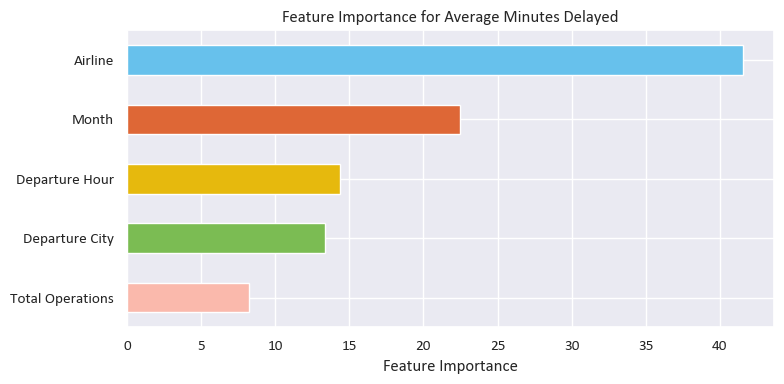


Feature Importance: average_delay_minutes
total_operations           8.21
origin_destination        13.35
departure_hour            14.37
month                     22.50
marketing_carrier_name    41.57
dtype: float64


In [26]:
import matplotlib.pyplot as plt

for target in targets:
    importance = pd.Series(
        models[target].feature_importances_,
        index=predictors
    ).sort_values()

    importance.plot(
        kind="barh",
        figsize=(8, 4),
        color = ["#fab9ac", "#7bbc53", "#e6b90d", "#de6736", "#67c1ec"],
        title="Feature Importance for Average Minutes Delayed"
    )
    plt.yticks(ticks=range(len(importance)), labels = ["Total Operations", "Departure City", "Departure Hour", "Month", "Airline"])
    plt.xlabel("Feature Importance")
    plt.tight_layout()
    plt.savefig("feature_importance.png")
    plt.show()
    print(f"\nFeature Importance: {target}")
    print(importance.round(2))

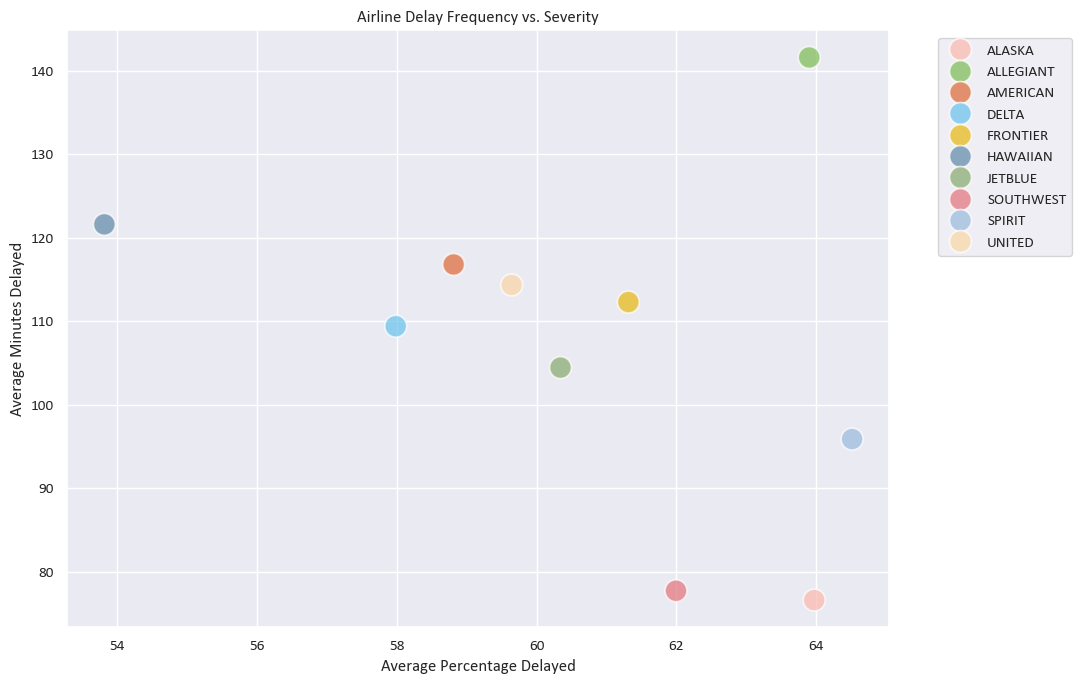

marketing_carrier_name  avg_delay  avg_pct_delay
                ALASKA      76.61          63.97
             ALLEGIANT     141.61          63.90
              AMERICAN     116.82          58.81
                 DELTA     109.42          57.99
              FRONTIER     112.31          61.31
              HAWAIIAN     121.62          53.82
               JETBLUE     104.46          60.34
             SOUTHWEST      77.73          62.00
                SPIRIT      95.90          64.52
                UNITED     114.36          59.64


In [13]:
airline_summary = (
    df.groupby("marketing_carrier_name")
    .agg(
        avg_delay=("average_delay_minutes", "mean"),
        avg_pct_delay=("percentage_delay", "mean")
    )
    .reset_index()
)

airline_colors = {
    "ALASKA": "#fab9ac",
    "ALLEGIANT": "#7bbc53",
    "AMERICAN": "#de6736",
    "DELTA": "#67c1ec",
    "FRONTIER": "#e6b90d",
    "HAWAIIAN": "#5d8aa8",
    "JETBLUE": "#87a96b",
    "SOUTHWEST": "#e4717a",
    "SPIRIT": "#99badd",
    "UNITED": "#fad6a5"
}

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=airline_summary,
    x="avg_pct_delay",
    y="avg_delay",
    hue="marketing_carrier_name",
    palette=airline_colors,
    s=250,
    alpha=0.7
)

plt.title("Airline Delay Frequency vs. Severity")
plt.xlabel("Average Percentage Delayed")
plt.ylabel("Average Minutes Delayed")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.savefig("delay_by_airline.png")
plt.show()
print(airline_summary.round(2).to_string(index=False))